# Jegadeesh and Titman (1993) — Table I: Extension to the 2024 Year-End Cutoff

This notebook reproduces **Table I: Returns of Relative Strength Portfolios** using CRSP on the WRDS server.

The target is deliberately narrow: construct the 32 \((J,K)\) strategies in **Panel A** and **Panel B**, report the Sell, Buy, and Buy-minus-Sell returns, and compare every published cell with the replication. The notebook follows the same sequence throughout:

1. portfolio construction;
2. timing;
3. key setup;
4. SQL and data checks;
5. portfolio returns;
6. paper-versus-replication diagnostics;
7. exploratory figures.

The reported return sample is **January 1965 through December 2024**.


**2024 extension.** This copy keeps the original legacy CRSP tables and portfolio-construction rules, with a data cutoff of **2024-12-31**. The original notebook is unchanged. Run all cells with your WRDS access; previous outputs were cleared. Separate cache and result folders prevent reuse of the original short-sample data or overwriting its results.

Published paper values remain historical benchmarks. Differences from this longer sample reflect the changed sample period and should not be interpreted as replication errors. This uses current historical data, not a point-in-time database snapshot as of 2024.


## 1. Table I construction — step by step

### Step 1 — Convert CRSP daily returns to monthly returns

The paper starts from the CRSP **daily** return file. For stock \(i\) in calendar month \(m\),

$$
R_{i,m}=\prod_{d\in m}(1+r_{i,d})-1.
$$

This monthly return is used both to form the ranking signal in Panel A and to measure holding-period returns in both panels.

### Step 2 — Measure the past-return signal

At the beginning of formation month \(t\), stocks are ranked by their compounded return over a \(J\)-month ranking period:

$$
S_{i,t}^{(J)}=\prod_{m\in\mathcal R_t^{(J)}}(1+R_{i,m})-1,
\qquad J\in\{3,6,9,12\}.
$$

- **Panel A:** \(\mathcal R_t^{(J)}=\{t-J,\ldots,t-1\}\); formation follows immediately.
- **Panel B:** the ranking period ends one week before formation; the notebook implements one week as five CRSP trading days.

Within each formation date, stocks are sorted in ascending order into ten equal-weighted portfolios:

- \(P1\): lowest past return = **Losers / Sell**;
- \(P10\): highest past return = **Winners / Buy**.

### Step 3 — Hold each formation cohort for \(K\) months

A cohort formed in month \(s\) is held in months \(s,s+1,\ldots,s+K-1\), where \(K\in\{3,6,9,12\}\). Because the paper reports the monthly-rebalanced version, the return of cohort \(s\), portfolio \(p\), in holding month \(t\) is the equal-weighted average of constituent stock returns available in that month:

$$
R^{\text{cohort}}_{p,s,t}
=
\frac{1}{N_{p,s,t}}
\sum_{i\in P_{p,s}}R_{i,t}.
$$

### Step 4 — Combine overlapping cohorts

A \(K\)-month strategy holds the current cohort and the previous \(K-1\) cohorts. The reported portfolio return in month \(t\) is therefore

$$
R_{p,t}^{(J,K)}
=
\frac{1}{K}
\sum_{h=0}^{K-1}
R^{\text{cohort}}_{p,t-h,t}.
$$

The zero-cost relative-strength return is

$$
R_{W-L,t}^{(J,K)}=R_{P10,t}^{(J,K)}-R_{P1,t}^{(J,K)}.
$$

### Step 5 — Report Table I statistics

For each Sell, Buy, and Buy-minus-Sell series, Table I reports the time-series mean and its conventional mean-return \(t\)-statistic:

$$
\bar R=\frac{1}{T}\sum_{t=1}^{T}R_t,
\qquad
 t(\bar R)=\frac{\bar R}{s(R)/\sqrt{T}},
\qquad T=\text{number of nonmissing monthly returns (target: 720)}.
$$

The construction order matters: first calculate a return for each formation cohort, then average the \(K\) active cohort returns. Pooling all stocks across cohorts would implicitly overweight larger formation cohorts and would not reproduce the paper's overlapping-portfolio design.


## 2. Timeline

### Panel A example: \(J=6\), \(K=6\), January 1965 formation

| Stage | Calendar time | What happens |
|---|---|---|
| Ranking | July–December 1964 | Compound six complete monthly returns and assign momentum deciles |
| Formation | Beginning of January 1965 | Buy \(P10\), sell \(P1\) |
| Cohort holding period | January–June 1965 | Rebalance the original cohort to equal weights each month |
| June 1965 strategy return | June 1965 | Equal-weight the six active cohorts formed from January through June |

```text
Jul 1964 ---------------- Dec 1964 | Jan 1965 ---------------- Jun 1965
        ranking window             | formation      cohort held for K=6
```

### Panel B timing

```text
ranking window                      skipped week                 holding
<--------------------------------> | d-5 d-4 d-3 d-2 d-1 | d0 ---------------->
                                   |<-- five trading days -->| first trading day
```

The skipped week is not an alternative holding period. It is a **timing robustness test**: it separates the medium-horizon ranking signal from bid–ask bounce, temporary price pressure, and very short-run lagged-price-reaction effects.

### Why pre-1965 cohorts are needed

For a \(K=12\) return in January 1965, the strategy must already contain twelve active cohorts. The code therefore begins portfolio formation in February 1964, even though only January 1965–December 2024 returns enter Table I.


## 3. Key setup

| Item | Baseline used here | Status |
|---|---|---|
| Target table | Table I, Panels A and B | Paper |
| Raw return data | `crsp.dsf`, one row per PERMNO–trading day | Paper-aligned |
| Reported sample | January 1965–December 2024 | Extended sample |
| Universe | NYSE and AMEX; CRSP common shares 10/11 | Exchange restriction is in the paper; share-code filter is an implementation choice |
| Ranking / holding horizons | \(J,K\in\{3,6,9,12\}\) months | Paper |
| Portfolio weights | Equal weight; monthly rebalancing | Paper |
| Overlap | Current cohort plus previous \(K-1\) cohorts | Paper |
| Panel B gap | Five CRSP trading days | One week is in the paper; exact trading-day convention is not reported |
| Ranking eligibility | Complete \(J\)-month history in Panel A; a daily history spanning the Panel B window | Paper-aligned implementation |
| Ties | SAS-style average ranks before assigning ten groups | Implementation choice |
| Missing holding return | Excluded from that cohort-month equal-weighted average; never set mechanically to zero | Implementation choice |
| Inference | Conventional time-series \(t\)-statistic of 720 monthly returns (1965-2024) | Table I convention |
| Data vintage | Current historical CRSP on WRDS | Replication limitation |

The baseline is selected from the paper's stated design rather than tuned to minimize numerical deviations. Sensitivity switches are collected at the end of the notebook.


In [1]:
# ============================================================
# Logic
# 1. Define the paper sample and strategy settings.
# 2. Create cache/result folders for WRDS reruns.
# 3. Load shared ranking, display, and plotting helpers.
#
# Output:
#   db, constants, load_or_query(), ntile_series(), plot_heatmap()
# ============================================================

from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wrds

from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

RAW_START = "1962-07-01"
RAW_END   = "2024-12-31"

SAMPLE_START = pd.Timestamp("1965-01-31")
SAMPLE_END   = pd.Timestamp(RAW_END)
EXPECTED_MONTHS = len(pd.period_range(SAMPLE_START, SAMPLE_END, freq="M"))

JS = [3, 6, 9, 12]
KS = [3, 6, 9, 12]

EXCHANGES = [1, 2]
COMMON_ONLY = True
DECILE_METHOD = "sas"              # "sas" or "first"
FILL_MISSING_MONTHLY_RET = False
PANEL_B_GAP_TRADING_DAYS = 5

START_ID = SAMPLE_START.year * 12 + SAMPLE_START.month
END_ID   = SAMPLE_END.year * 12 + SAMPLE_END.month
FORMATION_MIN_ID = START_ID - (max(KS) - 1)
FORMATION_MAX_ID = END_ID

CACHE  = Path.home() / "jt1993_table1_cache_v3_2024"
RESULT = Path.home() / "jt1993_table1_results_v3_2024"
CACHE.mkdir(parents=True, exist_ok=True)
RESULT.mkdir(parents=True, exist_ok=True)

db = wrds.Connection()


def load_or_query(name, sql, date_cols=None):
    """Read a cached parquet file or execute the SQL once on WRDS."""
    path = CACHE / name

    if path.exists():
        df = pd.read_parquet(path)
        source = "Loaded"
    else:
        df = db.raw_sql(sql, date_cols=date_cols) if date_cols else db.raw_sql(sql)
        df.to_parquet(path, index=False)
        source = "Saved"

    for col in date_cols or []:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col])

    print(f"{source}: {path.name}")
    return df


def month_id_to_month_end(values):
    """Convert year*12+month identifiers to calendar month-end timestamps."""
    s = pd.Series(values, dtype="int64")
    year = (s - 1) // 12
    month = (s - 1) % 12 + 1
    return pd.to_datetime({"year": year, "month": month, "day": 1}) + pd.offsets.MonthEnd(0)


def ntile_series(s, n=10, method=DECILE_METHOD):
    """Ascending n-tile assignment with an explicit tie convention."""
    out = pd.Series(pd.NA, index=s.index, dtype="Int64")
    valid = s.dropna()

    if len(valid) < n:
        return out

    if method == "sas":
        ranks = valid.rank(method="average")
        groups = np.floor(ranks * n / (len(valid) + 1)).astype(int) + 1
    elif method == "first":
        ranks = valid.rank(method="first")
        groups = pd.qcut(ranks, n, labels=False).astype(int) + 1
    else:
        raise ValueError("method must be 'sas' or 'first'")

    out.loc[valid.index] = np.clip(groups, 1, n)
    return out


def mean_tstat(s):
    x = pd.to_numeric(s, errors="coerce").dropna().astype(float)
    mean = x.mean()
    se = x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan
    return {"mean": mean, "t": mean / se if se > 0 else np.nan, "n": len(x)}


def plot_heatmap(data, title, value_fmt=".2f", xlabel="K", ylabel="J"):
    """Small matplotlib-only annotated heatmap."""
    arr = data.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    image = ax.imshow(arr, aspect="auto")

    ax.set_xticks(np.arange(len(data.columns)), labels=data.columns)
    ax.set_yticks(np.arange(len(data.index)), labels=data.index)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

    for i in range(arr.shape[0]):
        for j in range(arr.shape[1]):
            if np.isfinite(arr[i, j]):
                ax.text(j, i, format(arr[i, j], value_fmt), ha="center", va="center")

    fig.colorbar(image, ax=ax, shrink=0.82)
    plt.tight_layout()
    plt.show()


settings = pd.DataFrame({
    "Setting": ["Raw dates", "Reported dates", "J", "K", "Panel B gap", "Cache", "Results"],
    "Value": [RAW_START + " to " + RAW_END, f"{SAMPLE_START:%Y-%m} to {SAMPLE_END:%Y-%m}",
              str(JS), str(KS), f"{PANEL_B_GAP_TRADING_DAYS} trading days", str(CACHE), str(RESULT)],
})

display(settings)


WRDS recommends setting up a .pgpass file.
pgpass file created at C:\Users\phil_prod\AppData\Roaming\postgresql\pgpass.conf
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done


,Setting,Value
0,Raw dates,1962-07-01 to 2024-12-31
1,Reported dates,1965-01 to 2024-12
2,J,"[3, 6, 9, 12]"
3,K,"[3, 6, 9, 12]"
4,Panel B gap,5 trading days
5,Cache,C:\Users\phil_prod\jt1993_table1_cache_v3_2024
6,Results,C:\Users\phil_prod\jt1993_table1_results_v3_2024


## 4. Data extraction and SQL logic

| Query | WRDS table | Native frequency | Python output | Why this frequency is used |
|---|---|---|---|---|
| Monthly-return query | `crsp.dsf` + `crsp.msenames` | Daily | One row per PERMNO–month | Panel A ranking and all holding returns are monthly; daily returns are compounded on the server |
| Panel B query | `crsp.dsf` + `crsp.msenames` | Daily | One row per PERMNO–trading day | A one-week gap cannot be recovered from already-compounded monthly returns |

The date-range join to `msenames` applies the exchange and share-code filters using the security classification valid on each trading day. In the monthly query,

```sql
exp(sum(ln(1 + ret))) - 1
```

implements geometric compounding. A daily return of \(-1\) forces the monthly gross return to zero; a month with no valid daily return remains missing. The SQL performs the large daily-to-monthly aggregation on WRDS and downloads only the compact stock-month panel.


In [2]:
# ============================================================
# Logic
# 1. Read CRSP daily returns and historical security names.
# 2. Apply NYSE/AMEX and common-share filters at each date.
# 3. Compound daily returns to one PERMNO-month on WRDS.
#
# Output:
#   crsp_m  = one row per PERMNO-month
#   sample_m = January 1965-December 2024 stock-month panel
# ============================================================

share_filter = "and b.shrcd in (10, 11)" if COMMON_ONLY else ""
exchange_sql = ", ".join(map(str, EXCHANGES))

sql_monthly = f"""
with daily as (
    select
        a.permno,
        date_trunc('month', a.date)::date as month,
        a.ret
    from crsp.dsf as a
    inner join crsp.msenames as b
        on a.permno = b.permno
       and b.namedt <= a.date
       and a.date <= coalesce(b.nameendt, date '9999-12-31')
    where a.date between date '{RAW_START}' and date '{RAW_END}'
      and b.exchcd in ({exchange_sql})
      {share_filter}
)
select
    permno,
    month,
    count(*) as n_daily_rows,
    sum(case when ret is not null and ret >= -1 then 1 else 0 end) as n_valid_ret,
    case
        when sum(case when ret is not null and ret >= -1 then 1 else 0 end) = 0 then null
        when sum(case when ret = -1 then 1 else 0 end) > 0 then -1
        else exp(sum(case when ret > -1 then ln(1 + ret) else null end)) - 1
    end as ret
from daily
group by permno, month
order by permno, month
"""

t0 = time.time()
crsp_m = load_or_query(
    f"crsp_monthly_from_dsf_{RAW_START[:7].replace('-', '')}_{RAW_END[:7].replace('-', '')}.parquet",
    sql_monthly,
    date_cols=["month"],
).copy()

for col in ["permno", "n_daily_rows", "n_valid_ret"]:
    crsp_m[col] = pd.to_numeric(crsp_m[col], errors="coerce")
crsp_m["ret"] = pd.to_numeric(crsp_m["ret"], errors="coerce")
crsp_m["permno"] = crsp_m["permno"].astype("int32")
crsp_m["month"] = pd.to_datetime(crsp_m["month"]) + pd.offsets.MonthEnd(0)
crsp_m["month_id"] = crsp_m["month"].dt.year * 12 + crsp_m["month"].dt.month

crsp_m = (crsp_m.sort_values(["permno", "month"])
                 .drop_duplicates(["permno", "month"], keep="last")
                 .reset_index(drop=True))

sample_m = crsp_m.loc[crsp_m["month"].between(SAMPLE_START, SAMPLE_END)].copy()

print(f"Time used                   : {time.time() - t0:,.1f} seconds")
print(f"Rows                        : {len(crsp_m):,}")
print(f"Unique PERMNOs              : {crsp_m['permno'].nunique():,}")
print(f"Raw date range              : {crsp_m['month'].min():%Y-%m} to {crsp_m['month'].max():%Y-%m}")
print(f"Reported months             : {sample_m['month'].nunique():,} (target = {EXPECTED_MONTHS})")
print(f"Duplicate PERMNO-month rows : {crsp_m.duplicated(['permno', 'month']).sum():,}")

expected = pd.period_range(SAMPLE_START, SAMPLE_END, freq="M")
observed = pd.PeriodIndex(sample_m.loc[sample_m["ret"].notna(), "month"].dt.to_period("M").unique())
missing_months = expected.difference(observed)
if len(missing_months):
    raise ValueError(f"CRSP does not cover the requested sample: missing {list(missing_months)}")
display(crsp_m.head(8))


Saved: crsp_monthly_from_dsf_196207_202412.parquet
Time used                   : 47.0 seconds
Rows                        : 1,499,266
Unique PERMNOs              : 9,214
Raw date range              : 1962-07 to 2024-12
Reported months             : 720 (target = 720)
Duplicate PERMNO-month rows : 0


,permno,month,n_daily_rows,n_valid_ret,ret,month_id
0,10001,2009-12-31,9,9,0.190752,24120
1,10001,2010-01-31,19,19,-0.019063,24121
2,10001,2010-02-28,19,19,-0.000652,24122
3,10001,2010-03-31,23,23,0.020720,24123
4,10001,2010-04-30,21,21,0.124567,24124
5,10001,2010-05-31,20,20,0.005157,24125
6,10001,2010-06-30,22,22,-0.043732,24126
7,10001,2010-07-31,21,21,0.083604,24127


,Feature,Value
0,Observation unit,PERMNO-month
1,Rows,"1,439,184"
2,PERMNOs,"9,027"
3,Months,720
4,Missing monthly RET,0.062%
5,Date range,1965-01 to 2024-12


,count,mean,std,min,1%,5%,50%,95%,99%,max
ret,"1,438,293.000000",0.011593,0.150947,-0.991920,-0.333332,-0.184644,0.002495,0.224490,0.455410,26.583746


,n_stocks,n_returns,mean_ret,missing_rate,mean_ret_12m
month,,,,,
1965-01-31,2054,2054,0.071375,0.000000,NaN
1965-02-28,2062,2059,0.033443,0.001455,NaN
1965-03-31,2063,2061,0.015198,0.000969,NaN
1965-04-30,2067,2065,0.042398,0.000968,NaN
1965-05-31,2070,2070,-0.006347,0.000000,NaN


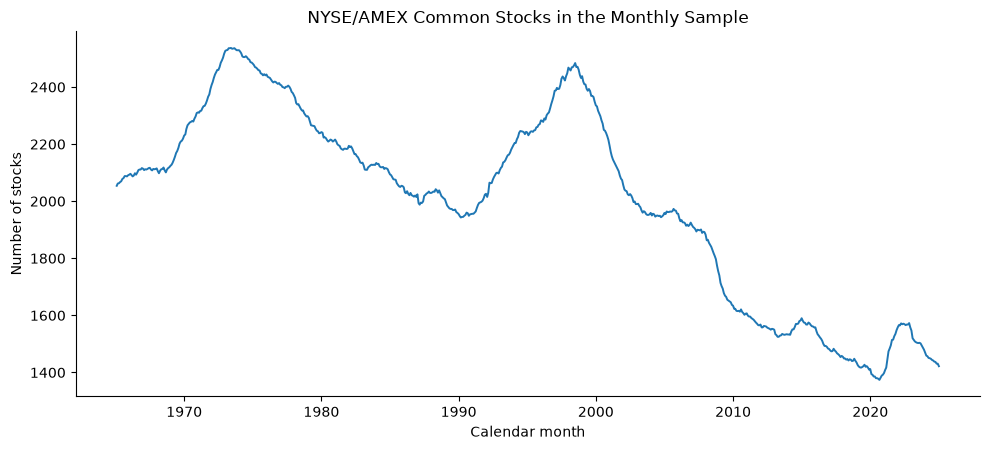

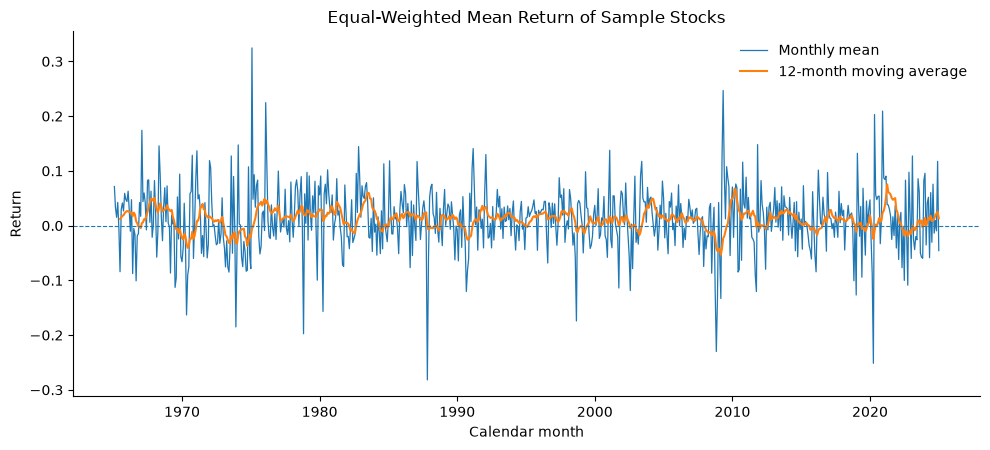

In [3]:
# ============================================================
# Logic
# 1. Inspect the stock-month panel and missing-return rate.
# 2. Plot sample coverage and the equal-weighted market return.
#
# Output:
#   monthly_coverage
# ============================================================

monthly_coverage = (
    sample_m.groupby("month")
            .agg(n_stocks=("permno", "nunique"), n_returns=("ret", "count"), mean_ret=("ret", "mean"))
)
monthly_coverage["missing_rate"] = 1 - monthly_coverage["n_returns"] / monthly_coverage["n_stocks"]
monthly_coverage["mean_ret_12m"] = monthly_coverage["mean_ret"].rolling(12, min_periods=6).mean()

structure = pd.DataFrame({
    "Feature": ["Observation unit", "Rows", "PERMNOs", "Months", "Missing monthly RET", "Date range"],
    "Value": ["PERMNO-month", f"{len(sample_m):,}", f"{sample_m['permno'].nunique():,}",
              f"{sample_m['month'].nunique():,}", f"{sample_m['ret'].isna().mean():.3%}",
              f"{sample_m['month'].min():%Y-%m} to {sample_m['month'].max():%Y-%m}"],
})

display(structure)
display(sample_m["ret"].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]).to_frame().T)
display(monthly_coverage.head())

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(monthly_coverage.index, monthly_coverage["n_stocks"], linewidth=1.4)
ax.set_title("NYSE/AMEX Common Stocks in the Monthly Sample")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Number of stocks")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(monthly_coverage.index, monthly_coverage["mean_ret"], linewidth=0.9, label="Monthly mean")
ax.plot(monthly_coverage.index, monthly_coverage["mean_ret_12m"], linewidth=1.5, label="12-month moving average")
ax.axhline(0, linewidth=0.8, linestyle="--")
ax.set_title("Equal-Weighted Mean Return of Sample Stocks")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Return")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


## 5. Panel A — immediate formation

Panel A uses \(J\) complete calendar months ending in month \(t-1\), forms the portfolio at the beginning of month \(t\), and earns its first holding return in month \(t\).

The functions below separate four objects that are often accidentally mixed together:

1. a stock's ranking signal;
2. its formation-cohort membership;
3. the return of one cohort in one holding month;
4. the average return of the \(K\) active cohorts.

This separation makes the overlap and equal-weighting logic directly auditable.


In [4]:
# ============================================================
# Logic
# 1. Form Panel A momentum deciles from J monthly returns.
# 2. Expand only P1/P10 constituents over the maximum holding horizon.
# 3. Compute cohort returns, then average K active cohorts.
#
# Input:
#   crsp_m
#
# Output:
#   make_panel_a_ranks(), build_cohort_returns(), summarize_strategy()
# ============================================================


def make_panel_a_ranks(monthly, J, fill_missing=FILL_MISSING_MONTHLY_RET,
                       decile_method=DECILE_METHOD, verbose=True):
    x = monthly[["permno", "month", "month_id", "ret"]].copy()
    x = x.sort_values(["permno", "month_id"]).reset_index(drop=True)

    r = pd.to_numeric(x["ret"], errors="coerce").astype(float).where(lambda s: s >= -1)
    if fill_missing:
        r = r.fillna(0.0)

    valid = r.notna()
    minus_one = r.eq(-1) & valid
    x["loggross"] = np.where(r.gt(-1) & valid, np.log1p(r), np.where(minus_one, 0.0, np.nan))
    x["minus_one"] = minus_one.astype("int8")

    g = x.groupby("permno", sort=False)
    x["signal_log"] = g["loggross"].rolling(J, min_periods=J).sum().reset_index(level=0, drop=True)
    x["zero_count"] = g["minus_one"].rolling(J, min_periods=J).sum().reset_index(level=0, drop=True)
    x["first_month_id"] = g["month_id"].shift(J - 1)

    complete = x["month_id"].sub(x["first_month_id"]).eq(J - 1)
    x["signal"] = np.expm1(x["signal_log"])
    x.loc[x["zero_count"].gt(0), "signal"] = -1.0
    x.loc[~complete, "signal"] = np.nan
    x["formation_id"] = x["month_id"] + 1

    rank = x.loc[
        x["signal"].notna() & x["formation_id"].between(FORMATION_MIN_ID, FORMATION_MAX_ID),
        ["permno", "month", "month_id", "formation_id", "signal"],
    ].copy()

    rank = rank.rename(columns={"month": "rank_end_month", "month_id": "rank_end_id"})
    rank["formation_month"] = month_id_to_month_end(rank["formation_id"]).to_numpy()
    rank["momr"] = rank.groupby("formation_id", group_keys=False)["signal"].transform(
        lambda s: ntile_series(s, 10, decile_method)
    )
    rank = rank.dropna(subset=["momr"]).copy()
    rank["momr"] = rank["momr"].astype("int8")

    if verbose:
        n_form = rank.groupby("formation_id")["permno"].nunique()
        n_decile = rank.groupby(["formation_id", "momr"])["permno"].size()
        print(f"Panel A, J={J}: {len(rank):,} stock-formation rows")
        print(f"Formation months : {rank['formation_id'].nunique():,}")
        print(f"Stocks per month : mean={n_form.mean():,.1f}, min={n_form.min():,}")
        print(f"Decile size      : min={n_decile.min():,}, max={n_decile.max():,}")

    return rank[["permno", "rank_end_month", "rank_end_id", "formation_month",
                 "formation_id", "signal", "momr"]]


def build_cohort_returns(rank, monthly, max_k=max(KS), verbose=True):
    """Return one row per formation cohort, holding month, and extreme decile."""
    base = rank.loc[rank["momr"].isin([1, 10]), ["permno", "formation_id", "momr"]].copy()
    ages = pd.DataFrame({"age": np.arange(max_k, dtype="int8")})
    expanded = base.merge(ages, how="cross")
    expanded["hold_id"] = expanded["formation_id"] + expanded["age"]

    hold = monthly[["permno", "month_id", "ret"]].rename(columns={"month_id": "hold_id"})
    merged = expanded.merge(hold, on=["permno", "hold_id"], how="left", validate="many_to_one")

    cohort = (
        merged.groupby(["formation_id", "hold_id", "age", "momr"], as_index=False)
              .agg(cohort_ret=("ret", "mean"), n_constituents=("permno", "size"), n_with_ret=("ret", "count"))
    )

    if verbose:
        print(f"Expanded extreme-decile rows : {len(expanded):,}")
        print(f"Matched holding returns      : {merged['ret'].notna().sum():,} ({merged['ret'].notna().mean():.2%})")
        print(f"Cohort-return rows           : {len(cohort):,}")

    return cohort


def summarize_strategy(cohort, K):
    """Average K cohort returns in each calendar month and report Table I statistics."""
    x = cohort.loc[
        cohort["age"].lt(K) & cohort["hold_id"].between(START_ID, END_ID)
    ].copy()

    portfolio = (
        x.groupby(["hold_id", "momr"], as_index=False)
         .agg(ret=("cohort_ret", "mean"), n_cohorts=("cohort_ret", "count"),
              n_active=("formation_id", "nunique"))
    )
    portfolio.loc[portfolio["n_cohorts"].lt(K), "ret"] = np.nan

    ret = portfolio.pivot(index="hold_id", columns="momr", values="ret").reindex(columns=[1, 10])
    active = portfolio.pivot(index="hold_id", columns="momr", values="n_active").reindex(columns=[1, 10])

    ts = ret.rename(columns={1: "loser", 10: "winner"})
    ts["buy_sell"] = ts["winner"] - ts["loser"]
    ts = ts.reindex(range(START_ID, END_ID + 1))

    results = {leg: mean_tstat(ts[leg]) for leg in ["loser", "winner", "buy_sell"]}
    return results, ts, active


print("Panel A helper functions loaded.")


Panel A helper functions loaded.


Panel A, J=6: 1,424,363 stock-formation rows
Formation months : 731
Stocks per month : mean=1,948.5, min=1,340
Decile size      : min=134, max=250
Expanded extreme-decile rows : 3,411,288
Matched holding returns      : 3,154,622 (92.48%)
Cohort-return rows           : 17,544


,Portfolio,Replication,Paper,Difference (bp/month),Replication t,Paper t,N months
0,loser,0.008413,0.007900,5.128454,2.283906,1.560000,720
1,winner,0.015209,0.017400,-21.911073,6.252822,4.330000,720
2,buy_sell,0.006796,0.009500,-27.039527,2.681382,3.070000,720


momr,P1,P10
count,720.000000,720.000000
mean,6.000000,6.000000
std,0.000000,0.000000
min,6.000000,6.000000
25%,6.000000,6.000000
50%,6.000000,6.000000
75%,6.000000,6.000000
max,6.000000,6.000000


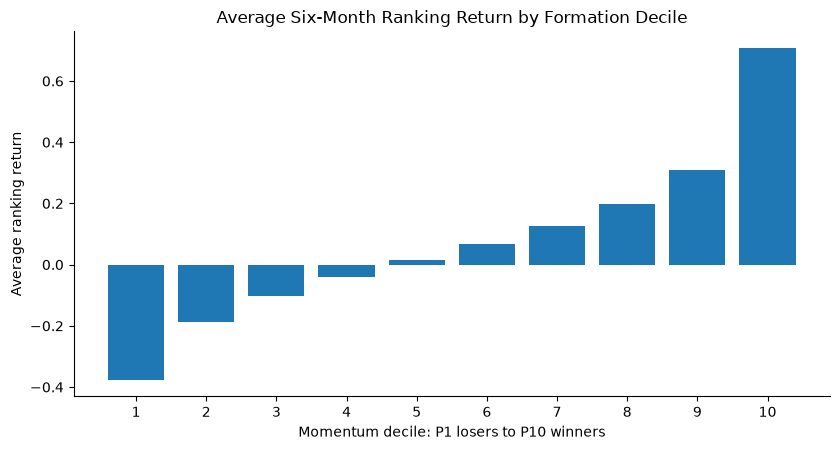

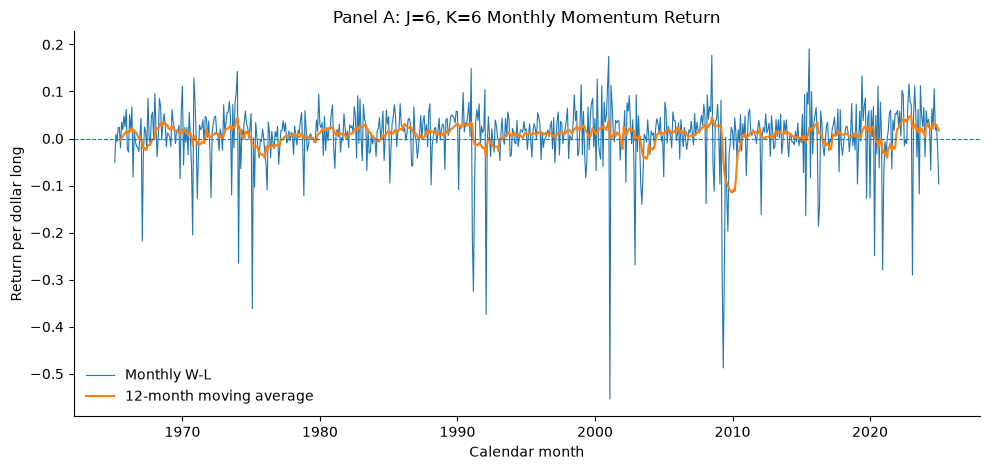

In [5]:
# ============================================================
# Logic
# 1. Store the published Table I benchmarks.
# 2. Run J=6, K=6 as a transparent checkpoint.
# 3. Inspect ranking monotonicity and the monthly W-L series.
#
# Output:
#   rank_a6, cohort_a6, ts_a66, check_a66
# ============================================================

PAPER_A = {
    (3,3):  {"loser":(0.0108,2.16), "winner":(0.0140,3.57), "buy_sell":(0.0032,1.10)},
    (3,6):  {"loser":(0.0091,1.87), "winner":(0.0149,3.78), "buy_sell":(0.0058,2.29)},
    (3,9):  {"loser":(0.0092,1.92), "winner":(0.0152,3.83), "buy_sell":(0.0061,2.69)},
    (3,12): {"loser":(0.0087,1.87), "winner":(0.0156,3.89), "buy_sell":(0.0069,3.53)},
    (6,3):  {"loser":(0.0087,1.67), "winner":(0.0171,4.28), "buy_sell":(0.0084,2.44)},
    (6,6):  {"loser":(0.0079,1.56), "winner":(0.0174,4.33), "buy_sell":(0.0095,3.07)},
    (6,9):  {"loser":(0.0072,1.48), "winner":(0.0174,4.31), "buy_sell":(0.0102,3.76)},
    (6,12): {"loser":(0.0080,1.66), "winner":(0.0166,4.13), "buy_sell":(0.0086,3.36)},
    (9,3):  {"loser":(0.0077,1.47), "winner":(0.0186,4.56), "buy_sell":(0.0109,3.03)},
    (9,6):  {"loser":(0.0065,1.29), "winner":(0.0186,4.53), "buy_sell":(0.0121,3.78)},
    (9,9):  {"loser":(0.0071,1.43), "winner":(0.0176,4.30), "buy_sell":(0.0105,3.47)},
    (9,12): {"loser":(0.0082,1.66), "winner":(0.0164,4.03), "buy_sell":(0.0082,2.89)},
    (12,3): {"loser":(0.0060,1.17), "winner":(0.0192,4.63), "buy_sell":(0.0131,3.74)},
    (12,6): {"loser":(0.0065,1.29), "winner":(0.0179,4.36), "buy_sell":(0.0114,3.40)},
    (12,9): {"loser":(0.0075,1.48), "winner":(0.0168,4.10), "buy_sell":(0.0093,2.95)},
    (12,12):{"loser":(0.0087,1.74), "winner":(0.0155,3.81), "buy_sell":(0.0068,2.25)},
}

PAPER_B = {
    (3,3):  {"loser":(0.0083,1.67), "winner":(0.0156,3.95), "buy_sell":(0.0073,2.61)},
    (3,6):  {"loser":(0.0079,1.64), "winner":(0.0158,3.98), "buy_sell":(0.0078,3.16)},
    (3,9):  {"loser":(0.0084,1.77), "winner":(0.0158,3.96), "buy_sell":(0.0074,3.36)},
    (3,12): {"loser":(0.0083,1.79), "winner":(0.0160,3.98), "buy_sell":(0.0077,4.00)},
    (6,3):  {"loser":(0.0066,1.28), "winner":(0.0179,4.47), "buy_sell":(0.0114,3.37)},
    (6,6):  {"loser":(0.0068,1.35), "winner":(0.0178,4.41), "buy_sell":(0.0110,3.61)},
    (6,9):  {"loser":(0.0067,1.38), "winner":(0.0175,4.32), "buy_sell":(0.0108,4.01)},
    (6,12): {"loser":(0.0076,1.58), "winner":(0.0166,4.13), "buy_sell":(0.0090,3.54)},
    (9,3):  {"loser":(0.0058,1.13), "winner":(0.0193,4.72), "buy_sell":(0.0135,3.85)},
    (9,6):  {"loser":(0.0058,1.15), "winner":(0.0188,4.56), "buy_sell":(0.0130,4.09)},
    (9,9):  {"loser":(0.0066,1.34), "winner":(0.0176,4.30), "buy_sell":(0.0109,3.67)},
    (9,12): {"loser":(0.0078,1.59), "winner":(0.0164,4.04), "buy_sell":(0.0085,3.04)},
    (12,3): {"loser":(0.0048,0.93), "winner":(0.0196,4.73), "buy_sell":(0.0149,4.28)},
    (12,6): {"loser":(0.0058,1.15), "winner":(0.0179,4.36), "buy_sell":(0.0121,3.65)},
    (12,9): {"loser":(0.0070,1.40), "winner":(0.0167,4.09), "buy_sell":(0.0096,3.09)},
    (12,12):{"loser":(0.0085,1.71), "winner":(0.0154,3.79), "buy_sell":(0.0069,2.31)},
}

rank_a6 = make_panel_a_ranks(crsp_m, J=6)
cohort_a6 = build_cohort_returns(rank_a6, crsp_m)
res_a66, ts_a66, active_a66 = summarize_strategy(cohort_a6, K=6)

check_a66 = pd.DataFrame([
    {
        "Portfolio": leg,
        "Replication": res_a66[leg]["mean"],
        "Paper": PAPER_A[(6, 6)][leg][0],
        "Difference (bp/month)": (res_a66[leg]["mean"] - PAPER_A[(6, 6)][leg][0]) * 10_000,
        "Replication t": res_a66[leg]["t"],
        "Paper t": PAPER_A[(6, 6)][leg][1],
        "N months": res_a66[leg]["n"],
    }
    for leg in ["loser", "winner", "buy_sell"]
])

display(check_a66)
display(active_a66.describe().rename(columns={1: "P1", 10: "P10"}))

signal_decile = rank_a6.groupby("momr")["signal"].mean().reindex(range(1, 11))
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.bar(signal_decile.index.astype(str), signal_decile.values)
ax.set_title("Average Six-Month Ranking Return by Formation Decile")
ax.set_xlabel("Momentum decile: P1 losers to P10 winners")
ax.set_ylabel("Average ranking return")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

plot_a66 = ts_a66.copy()
plot_a66.index = month_id_to_month_end(plot_a66.index).to_numpy()
plot_a66["buy_sell_12m"] = plot_a66["buy_sell"].rolling(12, min_periods=6).mean()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(plot_a66.index, plot_a66["buy_sell"], linewidth=0.8, label="Monthly W-L")
ax.plot(plot_a66.index, plot_a66["buy_sell_12m"], linewidth=1.5, label="12-month moving average")
ax.axhline(0, linewidth=0.8, linestyle="--")
ax.set_title("Panel A: J=6, K=6 Monthly Momentum Return")
ax.set_xlabel("Calendar month")
ax.set_ylabel("Return per dollar long")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


In [6]:
# ============================================================
# Logic
# 1. Reproduce every Panel A J-by-K strategy.
# 2. Store monthly time series and paper deviations.
#
# Output:
#   panel_a_compare, panel_a_ts, panel_a_rank_cache
# ============================================================

panel_a_rows = []
panel_a_ts = {}
panel_a_rank_cache = {6: rank_a6}
panel_a_cohort_cache = {6: cohort_a6}

for J in JS:
    print("\n" + "=" * 76)
    print(f"Panel A: J={J}")

    rank = panel_a_rank_cache.get(J)
    if rank is None:
        rank = make_panel_a_ranks(crsp_m, J)
        panel_a_rank_cache[J] = rank

    cohort = panel_a_cohort_cache.get(J)
    if cohort is None:
        cohort = build_cohort_returns(rank, crsp_m)
        panel_a_cohort_cache[J] = cohort

    for K in KS:
        result, ts, active = summarize_strategy(cohort, K)
        panel_a_ts[(J, K)] = ts

        print(f"K={K:2d} | Sell={result['loser']['mean']:.4f}  "
              f"Buy={result['winner']['mean']:.4f}  W-L={result['buy_sell']['mean']:.4f}")

        for leg in ["loser", "winner", "buy_sell"]:
            paper_mean, paper_t = PAPER_A[(J, K)][leg]
            panel_a_rows.append({
                "panel": "A", "J": J, "K": K, "leg": leg,
                "rep_mean": result[leg]["mean"], "paper_mean": paper_mean,
                "diff_bp": (result[leg]["mean"] - paper_mean) * 10_000,
                "rep_t": result[leg]["t"], "paper_t": paper_t,
                "t_diff": result[leg]["t"] - paper_t, "n": result[leg]["n"],
                "min_active_cohorts": active.min().min(),
            })

panel_a_compare = pd.DataFrame(panel_a_rows)
display(panel_a_compare)



Panel A: J=3
Panel A, J=3: 1,446,483 stock-formation rows
Formation months : 731
Stocks per month : mean=1,978.8, min=1,359
Decile size      : min=135, max=252
Expanded extreme-decile rows : 3,464,388
Matched holding returns      : 3,225,091 (93.09%)
Cohort-return rows           : 17,544
K= 3 | Sell=0.0111  Buy=0.0124  W-L=0.0013
K= 6 | Sell=0.0093  Buy=0.0132  W-L=0.0038
K= 9 | Sell=0.0092  Buy=0.0136  W-L=0.0044
K=12 | Sell=0.0089  Buy=0.0136  W-L=0.0047

Panel A: J=6
K= 3 | Sell=0.0094  Buy=0.0149  W-L=0.0055
K= 6 | Sell=0.0084  Buy=0.0152  W-L=0.0068
K= 9 | Sell=0.0079  Buy=0.0151  W-L=0.0072
K=12 | Sell=0.0089  Buy=0.0142  W-L=0.0053

Panel A: J=9
Panel A, J=9: 1,402,347 stock-formation rows
Formation months : 731
Stocks per month : mean=1,918.4, min=1,324
Decile size      : min=132, max=247
Expanded extreme-decile rows : 3,358,872
Matched holding returns      : 3,106,698 (92.49%)
Cohort-return rows           : 17,544
K= 3 | Sell=0.0088  Buy=0.0166  W-L=0.0078
K= 6 | Sell=0.0075 

,panel,J,K,leg,rep_mean,paper_mean,diff_bp,rep_t,paper_t,t_diff,n,min_active_cohorts
0,A,3,3,loser,0.011084,0.010800,2.842470,3.133889,2.160000,0.973889,720,3
1,A,3,3,winner,0.012393,0.014000,-16.067491,5.188554,3.570000,1.618554,720,3
2,A,3,3,buy_sell,0.001309,0.003200,-18.909960,0.590688,1.100000,-0.509312,720,3
3,A,3,6,loser,0.009329,0.009100,2.288650,2.729222,1.870000,0.859222,720,6
4,A,3,6,winner,0.013176,0.014900,-17.239632,5.421555,3.780000,1.641555,720,6
5,A,3,6,buy_sell,0.003847,0.005800,-19.528282,1.955179,2.290000,-0.334821,720,6
6,A,3,9,loser,0.009190,0.009200,-0.102239,2.727478,1.920000,0.807478,720,9
7,A,3,9,winner,0.013599,0.015200,-16.005795,5.598076,3.830000,1.768076,720,9
8,A,3,9,buy_sell,0.004410,0.006100,-16.903556,2.428768,2.690000,-0.261232,720,9
9,A,3,12,loser,0.008913,0.008700,2.128754,2.736483,1.870000,0.866483,720,12


## 6. Panel B — one-week gap

Panel B asks whether the Table I profits survive after removing the trading week immediately before formation. The purpose is to reduce contamination from the mechanisms emphasized in the short-horizon reversal literature:

- bid–ask bounce;
- temporary price pressure;
- illiquidity-related reversals;
- lagged reactions over only a few days.

A positive Panel B return therefore shows that the result is not merely the mechanical continuation or reversal of prices in the final trading days of the ranking period.

The paper states “one week” but does not disclose the original trading-calendar program. The baseline below uses **five trading days**, prints the exact skipped dates, and leaves nearby gap lengths as sensitivity checks.


In [7]:
# ============================================================
# Logic
# 1. Download the filtered CRSP daily panel needed for Panel B.
# 2. Keep daily frequency because the skipped week is date-specific.
#
# Output:
#   crsp_d, trading_days
# ============================================================

sql_daily = f"""
select
    a.permno,
    a.date,
    a.ret
from crsp.dsf as a
inner join crsp.msenames as b
    on a.permno = b.permno
   and b.namedt <= a.date
   and a.date <= coalesce(b.nameendt, date '9999-12-31')
where a.date between date '{RAW_START}' and date '{RAW_END}'
  and b.exchcd in ({exchange_sql})
  {share_filter}
order by a.permno, a.date
"""

t0 = time.time()
crsp_d = load_or_query(
    f"crsp_daily_panel_b_{RAW_START[:7].replace('-', '')}_{RAW_END[:7].replace('-', '')}.parquet",
    sql_daily,
    date_cols=["date"],
).copy()

crsp_d["permno"] = pd.to_numeric(crsp_d["permno"], errors="coerce").astype("int32")
crsp_d["date"] = pd.to_datetime(crsp_d["date"])
crsp_d["ret"] = pd.to_numeric(crsp_d["ret"], errors="coerce")
crsp_d = (crsp_d.sort_values(["permno", "date"])
                 .drop_duplicates(["permno", "date"], keep="last")
                 .reset_index(drop=True))

trading_days = np.sort(crsp_d["date"].drop_duplicates().to_numpy(dtype="datetime64[ns]"))

print(f"Time used                  : {time.time() - t0:,.1f} seconds")
print(f"Rows                       : {len(crsp_d):,}")
print(f"Unique PERMNOs             : {crsp_d['permno'].nunique():,}")
print(f"Trading days               : {len(trading_days):,}")
print(f"Missing daily RET          : {crsp_d['ret'].isna().mean():.3%}")
print(f"Duplicate PERMNO-date rows : {crsp_d.duplicated(['permno', 'date']).sum():,}")
print(f"Memory                     : {crsp_d.memory_usage(deep=True).sum() / 1024**3:,.2f} GB")

display(crsp_d.head(8))


Saved: crsp_daily_panel_b_196207_202412.parquet
Time used                  : 228.3 seconds
Rows                       : 31,303,929
Unique PERMNOs             : 9,214
Trading days               : 15,732
Missing daily RET          : 0.119%
Duplicate PERMNO-date rows : 0
Memory                     : 0.61 GB


,permno,date,ret
0,10001,2009-12-18,-0.031214
1,10001,2009-12-21,0.128878
2,10001,2009-12-22,0.097252
3,10001,2009-12-23,-0.007707
4,10001,2009-12-24,0.040777
5,10001,2009-12-28,0.002910
6,10001,2009-12-29,-0.018714
7,10001,2009-12-30,-0.031327


In [8]:
# ============================================================
# Logic
# 1. Map each formation month to its first trading day.
# 2. Skip the preceding five trading days.
# 3. Compound daily returns over the preceding J calendar months.
# 4. Assign deciles and reuse the Panel A holding functions.
#
# Output:
#   panel_b_windows(), make_panel_b_ranks(), panel_b_timing_check()
# ============================================================

formation_ids = np.arange(FORMATION_MIN_ID, FORMATION_MAX_ID + 1)
calendar = pd.DataFrame({"date": pd.to_datetime(trading_days)})
calendar["month_id"] = calendar["date"].dt.year * 12 + calendar["date"].dt.month
first_trade = calendar.groupby("month_id")["date"].min().to_dict()


def panel_b_windows(J, gap_days=PANEL_B_GAP_TRADING_DAYS):
    rows = []

    for formation_id in formation_ids:
        hold_start = first_trade.get(formation_id)
        if hold_start is None:
            continue

        pos = np.searchsorted(trading_days, np.datetime64(hold_start), side="left")
        signal_end_pos = pos - gap_days - 1
        if signal_end_pos < 0:
            continue

        signal_end = pd.Timestamp(trading_days[signal_end_pos])
        rows.append({
            "formation_id": formation_id,
            "formation_month": month_id_to_month_end([formation_id]).iloc[0],
            "hold_start": hold_start,
            "signal_start_boundary": signal_end - pd.DateOffset(months=J),
            "signal_end": signal_end,
        })

    return pd.DataFrame(rows)


def make_panel_b_ranks(daily, J, gap_days=PANEL_B_GAP_TRADING_DAYS,
                       decile_method=DECILE_METHOD, verbose=True):
    windows = panel_b_windows(J, gap_days)
    starts = windows["signal_start_boundary"].to_numpy(dtype="datetime64[ns]")
    ends = windows["signal_end"].to_numpy(dtype="datetime64[ns]")
    formation = windows["formation_id"].to_numpy(dtype=int)

    pieces = []
    groups = daily.groupby("permno", sort=False)
    n_permno = daily["permno"].nunique()
    t0 = time.time()

    for count, (permno, g) in enumerate(groups, start=1):
        dates = g["date"].to_numpy(dtype="datetime64[ns]")
        raw = pd.to_numeric(g["ret"], errors="coerce").to_numpy(dtype=float)
        valid = np.isfinite(raw) & (raw >= -1)
        ret = np.where(valid, raw, 0.0)

        minus_one = valid & (ret == -1)
        logret = np.zeros(len(ret), dtype=float)
        logret[valid & (ret > -1)] = np.log1p(ret[valid & (ret > -1)])

        cumlog = np.r_[0.0, np.cumsum(logret)]
        cumzero = np.r_[0, np.cumsum(minus_one.astype(np.int32))]
        cumvalid = np.r_[0, np.cumsum(valid.astype(np.int32))]

        left = np.searchsorted(dates, starts, side="right")
        right = np.searchsorted(dates, ends, side="right")
        valid_count = cumvalid[right] - cumvalid[left]

        spans_window = (dates[0] <= starts) & (dates[-1] >= ends) & (right > left) & (valid_count > 0)
        signal = np.expm1(cumlog[right] - cumlog[left])
        signal[(cumzero[right] - cumzero[left]) > 0] = -1.0
        signal[~spans_window] = np.nan

        keep = np.isfinite(signal)
        if keep.any():
            pieces.append(pd.DataFrame({
                "permno": np.int32(permno),
                "formation_id": formation[keep],
                "signal": signal[keep],
            }))

        if count % 1000 == 0 or count == n_permno:
            print(f"Processed {count:,}/{n_permno:,} PERMNOs ({time.time() - t0:,.1f}s)")

    rank = pd.concat(pieces, ignore_index=True)
    rank["formation_month"] = month_id_to_month_end(rank["formation_id"]).to_numpy()
    rank["momr"] = rank.groupby("formation_id", group_keys=False)["signal"].transform(
        lambda s: ntile_series(s, 10, decile_method)
    )
    rank = rank.dropna(subset=["momr"]).copy()
    rank["momr"] = rank["momr"].astype("int8")

    if verbose:
        n_form = rank.groupby("formation_id")["permno"].nunique()
        print(f"Panel B, J={J}: {len(rank):,} stock-formation rows")
        print(f"Formation months : {rank['formation_id'].nunique():,}")
        print(f"Stocks per month : mean={n_form.mean():,.1f}, min={n_form.min():,}")

    return rank[["permno", "formation_month", "formation_id", "signal", "momr"]]


def panel_b_timing_check(J=6, n=6):
    windows = panel_b_windows(J).loc[lambda x: x["formation_id"].between(START_ID, END_ID)].head(n).copy()
    skipped = []

    for _, row in windows.iterrows():
        pos = np.searchsorted(trading_days, np.datetime64(row["hold_start"]), side="left")
        dates = trading_days[pos - PANEL_B_GAP_TRADING_DAYS:pos]
        skipped.append(", ".join(pd.to_datetime(dates).strftime("%Y-%m-%d")))

    windows["skipped_days"] = skipped
    return windows[["formation_month", "signal_start_boundary", "signal_end", "skipped_days", "hold_start"]]


display(panel_b_timing_check(J=6, n=6))


,formation_month,signal_start_boundary,signal_end,skipped_days,hold_start
11,1965-01-31,1964-06-23,1964-12-23,"1964-12-24, 1964-12-28, 1964-12-29, 1964-12-30...",1965-01-04
12,1965-02-28,1964-07-22,1965-01-22,"1965-01-25, 1965-01-26, 1965-01-27, 1965-01-28...",1965-02-01
13,1965-03-31,1964-08-18,1965-02-18,"1965-02-19, 1965-02-23, 1965-02-24, 1965-02-25...",1965-03-01
14,1965-04-30,1964-09-24,1965-03-24,"1965-03-25, 1965-03-26, 1965-03-29, 1965-03-30...",1965-04-01
15,1965-05-31,1964-10-23,1965-04-23,"1965-04-26, 1965-04-27, 1965-04-28, 1965-04-29...",1965-05-03
16,1965-06-30,1964-11-21,1965-05-21,"1965-05-24, 1965-05-25, 1965-05-26, 1965-05-27...",1965-06-01


In [9]:
# ============================================================
# Logic
# 1. Run the Panel B J=6, K=6 checkpoint.
# 2. Reproduce all Panel B strategies.
#
# Output:
#   panel_b_compare, panel_b_ts, check_b66
# ============================================================

rank_b6 = make_panel_b_ranks(crsp_d, J=6)
cohort_b6 = build_cohort_returns(rank_b6, crsp_m)
res_b66, ts_b66, active_b66 = summarize_strategy(cohort_b6, K=6)

check_b66 = pd.DataFrame([
    {
        "Portfolio": leg,
        "Replication": res_b66[leg]["mean"],
        "Paper": PAPER_B[(6, 6)][leg][0],
        "Difference (bp/month)": (res_b66[leg]["mean"] - PAPER_B[(6, 6)][leg][0]) * 10_000,
        "Replication t": res_b66[leg]["t"],
        "Paper t": PAPER_B[(6, 6)][leg][1],
        "N months": res_b66[leg]["n"],
    }
    for leg in ["loser", "winner", "buy_sell"]
])

display(check_b66)

panel_b_rows = []
panel_b_ts = {}
panel_b_rank_cache = {6: rank_b6}
panel_b_cohort_cache = {6: cohort_b6}

for J in JS:
    print("\n" + "=" * 76)
    print(f"Panel B: J={J}")

    rank = panel_b_rank_cache.get(J)
    if rank is None:
        rank = make_panel_b_ranks(crsp_d, J)
        panel_b_rank_cache[J] = rank

    cohort = panel_b_cohort_cache.get(J)
    if cohort is None:
        cohort = build_cohort_returns(rank, crsp_m)
        panel_b_cohort_cache[J] = cohort

    for K in KS:
        result, ts, active = summarize_strategy(cohort, K)
        panel_b_ts[(J, K)] = ts

        print(f"K={K:2d} | Sell={result['loser']['mean']:.4f}  "
              f"Buy={result['winner']['mean']:.4f}  W-L={result['buy_sell']['mean']:.4f}")

        for leg in ["loser", "winner", "buy_sell"]:
            paper_mean, paper_t = PAPER_B[(J, K)][leg]
            panel_b_rows.append({
                "panel": "B", "J": J, "K": K, "leg": leg,
                "rep_mean": result[leg]["mean"], "paper_mean": paper_mean,
                "diff_bp": (result[leg]["mean"] - paper_mean) * 10_000,
                "rep_t": result[leg]["t"], "paper_t": paper_t,
                "t_diff": result[leg]["t"] - paper_t, "n": result[leg]["n"],
                "min_active_cohorts": active.min().min(),
            })

panel_b_compare = pd.DataFrame(panel_b_rows)
display(panel_b_compare)


Processed 1,000/9,214 PERMNOs (0.8s)
Processed 2,000/9,214 PERMNOs (1.0s)
Processed 3,000/9,214 PERMNOs (1.3s)
Processed 4,000/9,214 PERMNOs (1.5s)
Processed 5,000/9,214 PERMNOs (1.8s)
Processed 6,000/9,214 PERMNOs (2.1s)
Processed 7,000/9,214 PERMNOs (2.4s)
Processed 8,000/9,214 PERMNOs (2.6s)
Processed 9,000/9,214 PERMNOs (2.9s)
Processed 9,214/9,214 PERMNOs (2.9s)
Panel B, J=6: 1,413,606 stock-formation rows
Formation months : 731
Stocks per month : mean=1,933.8, min=1,331
Expanded extreme-decile rows : 3,385,656
Matched holding returns      : 3,153,718 (93.15%)
Cohort-return rows           : 17,544


,Portfolio,Replication,Paper,Difference (bp/month),Replication t,Paper t,N months
0,loser,0.007649,0.006800,8.489665,2.095630,1.350000,720
1,winner,0.015339,0.017800,-24.613991,6.308118,4.410000,720
2,buy_sell,0.007690,0.011000,-33.103656,3.086887,3.610000,720



Panel B: J=3
Processed 1,000/9,214 PERMNOs (0.8s)
Processed 2,000/9,214 PERMNOs (1.1s)
Processed 3,000/9,214 PERMNOs (1.4s)
Processed 4,000/9,214 PERMNOs (1.7s)
Processed 5,000/9,214 PERMNOs (1.9s)
Processed 6,000/9,214 PERMNOs (2.2s)
Processed 7,000/9,214 PERMNOs (2.5s)
Processed 8,000/9,214 PERMNOs (2.7s)
Processed 9,000/9,214 PERMNOs (2.9s)
Processed 9,214/9,214 PERMNOs (3.0s)
Panel B, J=3: 1,434,277 stock-formation rows
Formation months : 731
Stocks per month : mean=1,962.1, min=1,349
Expanded extreme-decile rows : 3,435,480
Matched holding returns      : 3,214,675 (93.57%)
Cohort-return rows           : 17,544
K= 3 | Sell=0.0089  Buy=0.0133  W-L=0.0044
K= 6 | Sell=0.0083  Buy=0.0135  W-L=0.0052
K= 9 | Sell=0.0085  Buy=0.0139  W-L=0.0053
K=12 | Sell=0.0086  Buy=0.0138  W-L=0.0052

Panel B: J=6
K= 3 | Sell=0.0078  Buy=0.0152  W-L=0.0075
K= 6 | Sell=0.0076  Buy=0.0153  W-L=0.0077
K= 9 | Sell=0.0076  Buy=0.0151  W-L=0.0075
K=12 | Sell=0.0087  Buy=0.0141  W-L=0.0055

Panel B: J=9
Proc

,panel,J,K,leg,rep_mean,paper_mean,diff_bp,rep_t,paper_t,t_diff,n,min_active_cohorts
0,B,3,3,loser,0.008921,0.008300,6.214984,2.553858,1.670000,0.883858,720,3
1,B,3,3,winner,0.013349,0.015600,-22.513623,5.566905,3.950000,1.616905,720,3
2,B,3,3,buy_sell,0.004427,0.007300,-28.728607,2.054461,2.610000,-0.555539,720,3
3,B,3,6,loser,0.008339,0.007900,4.389031,2.457549,1.640000,0.817549,720,6
4,B,3,6,winner,0.013536,0.015800,-22.644525,5.562261,3.980000,1.582261,720,6
5,B,3,6,buy_sell,0.005197,0.007800,-26.033556,2.707594,3.160000,-0.452406,720,6
6,B,3,9,loser,0.008529,0.008400,1.288015,2.554605,1.770000,0.784605,720,9
7,B,3,9,winner,0.013858,0.015800,-19.423207,5.700841,3.960000,1.740841,720,9
8,B,3,9,buy_sell,0.005329,0.007400,-20.711221,3.017872,3.360000,-0.342128,720,9
9,B,3,12,loser,0.008592,0.008300,2.919698,2.653555,1.790000,0.863555,720,12


## 7. Table I results: extended sample and historical paper benchmark

The tables below report the same three objects for each panel:

1. the paper's mean monthly return and \(t\)-statistic;
2. the replication's mean monthly return and \(t\)-statistic;
3. replication minus paper, measured in basis points per month for the Buy-minus-Sell return.

The visual diagnostics then answer three distinct questions:

- **Economic pattern:** where is momentum strongest across \(J\) and \(K\)?
- **Historical comparison:** how does the extended sample differ from the published sample?
- **Role of the skipped week:** how does Panel B change the same \((J,K)\) strategy relative to Panel A?


Panel A — published Table I: mean monthly return (t-statistic)


,J,Portfolio,K=3,K=6,K=9,K=12
0,3,Sell,0.0108 (2.16),0.0091 (1.87),0.0092 (1.92),0.0087 (1.87)
1,3,Buy,0.0140 (3.57),0.0149 (3.78),0.0152 (3.83),0.0156 (3.89)
2,3,Buy-Sell,0.0032 (1.10),0.0058 (2.29),0.0061 (2.69),0.0069 (3.53)
3,6,Sell,0.0087 (1.67),0.0079 (1.56),0.0072 (1.48),0.0080 (1.66)
4,6,Buy,0.0171 (4.28),0.0174 (4.33),0.0174 (4.31),0.0166 (4.13)
5,6,Buy-Sell,0.0084 (2.44),0.0095 (3.07),0.0102 (3.76),0.0086 (3.36)
6,9,Sell,0.0077 (1.47),0.0065 (1.29),0.0071 (1.43),0.0082 (1.66)
7,9,Buy,0.0186 (4.56),0.0186 (4.53),0.0176 (4.30),0.0164 (4.03)
8,9,Buy-Sell,0.0109 (3.03),0.0121 (3.78),0.0105 (3.47),0.0082 (2.89)
9,12,Sell,0.0060 (1.17),0.0065 (1.29),0.0075 (1.48),0.0087 (1.74)


Panel A — replication: mean monthly return (t-statistic)


,J,Portfolio,K=3,K=6,K=9,K=12
0,3,Sell,0.0111 (3.13),0.0093 (2.73),0.0092 (2.73),0.0089 (2.74)
1,3,Buy,0.0124 (5.19),0.0132 (5.42),0.0136 (5.60),0.0136 (5.55)
2,3,Buy-Sell,0.0013 (0.59),0.0038 (1.96),0.0044 (2.43),0.0047 (3.03)
3,6,Sell,0.0094 (2.50),0.0084 (2.28),0.0079 (2.24),0.0089 (2.57)
4,6,Buy,0.0149 (6.17),0.0152 (6.25),0.0151 (6.19),0.0142 (5.84)
5,6,Buy-Sell,0.0055 (2.01),0.0068 (2.68),0.0072 (3.20),0.0053 (2.58)
6,9,Sell,0.0088 (2.24),0.0075 (2.02),0.0083 (2.28),0.0095 (2.65)
7,9,Buy,0.0166 (6.80),0.0162 (6.55),0.0152 (6.19),0.0140 (5.73)
8,9,Buy-Sell,0.0078 (2.62),0.0086 (3.25),0.0068 (2.76),0.0045 (1.93)
9,12,Sell,0.0081 (2.08),0.0084 (2.23),0.0093 (2.50),0.0105 (2.86)


Panel A — replication minus paper: W-L basis points per month


...

Panel B — replication minus paper: W-L basis points per month


K,3,6,9,12
J,,,,
3,-28.728607,-26.033556,-20.711221,-24.695454
6,-39.052531,-33.103656,-32.786359,-35.203794
9,-40.188524,-39.101062,-38.319190,-38.765100
12,-60.688825,-53.520168,-48.653014,-43.775245


,Panel,MAE all returns (bp/month),Maximum absolute difference (bp/month),MAE W-L (bp/month),Maximum W-L difference (bp/month),MAE t-statistic,All series have 720 months
0,Panel A,22.040093,54.031554,33.053749,54.031554,1.116368,True
1,Panel B,25.180263,60.688825,37.707894,60.688825,1.143411,True


Ten largest return differences


,panel,J,K,leg,rep_mean,paper_mean,diff_bp,rep_t,paper_t
86,B,12,3,buy_sell,0.008831,0.014900,-60.688825,3.078975,4.280000
38,A,12,3,buy_sell,0.007697,0.013100,-54.031554,2.651536,3.740000
89,B,12,6,buy_sell,0.006748,0.012100,-53.520168,2.472382,3.650000
41,A,12,6,buy_sell,0.006508,0.011400,-48.915953,2.370764,3.400000
92,B,12,9,buy_sell,0.004735,0.009600,-48.653014,1.831817,3.090000
44,A,12,9,buy_sell,0.004693,0.009300,-46.065292,1.802163,2.950000
95,B,12,12,buy_sell,0.002522,0.006900,-43.775245,1.031595,2.310000
47,A,12,12,buy_sell,0.002547,0.006800,-42.529630,1.033252,2.250000
74,B,9,3,buy_sell,0.009481,0.013500,-40.188524,3.265593,3.850000
77,B,9,6,buy_sell,0.009090,0.013000,-39.101062,3.459661,4.090000


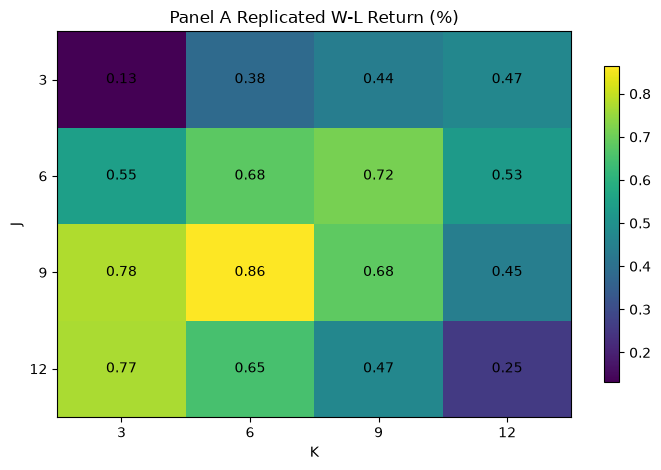

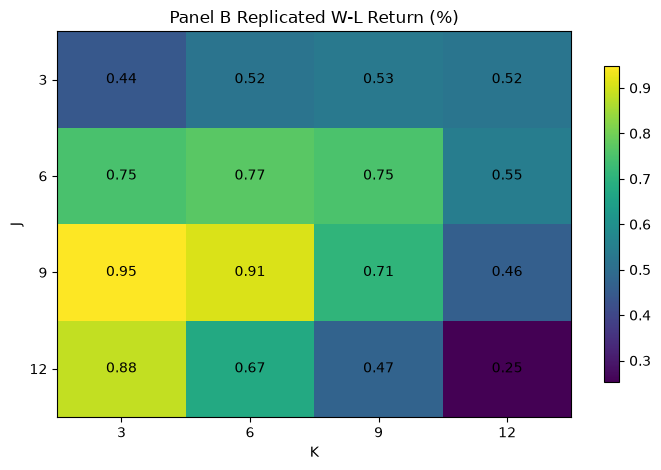

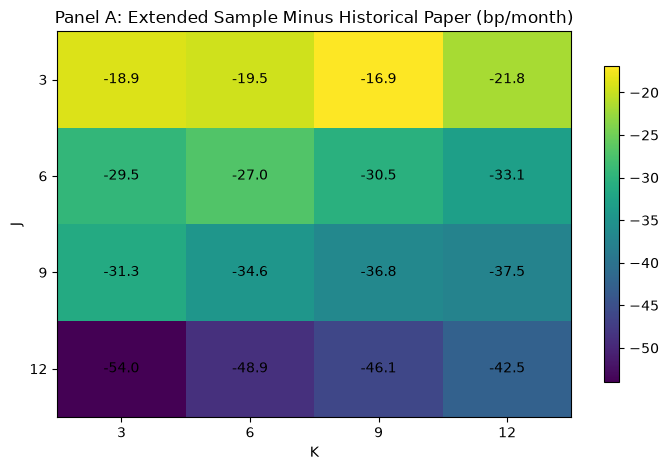

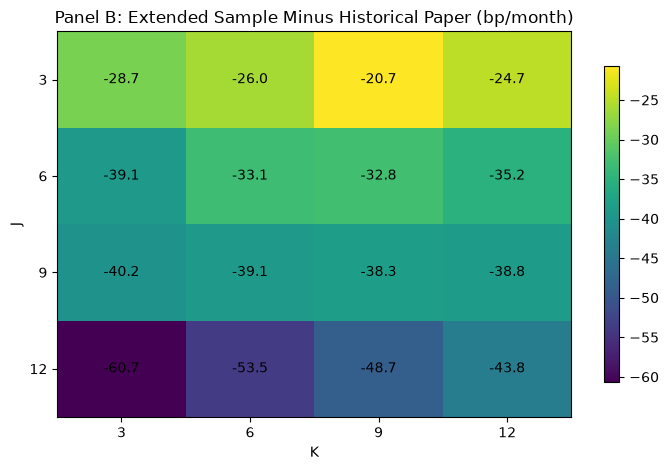

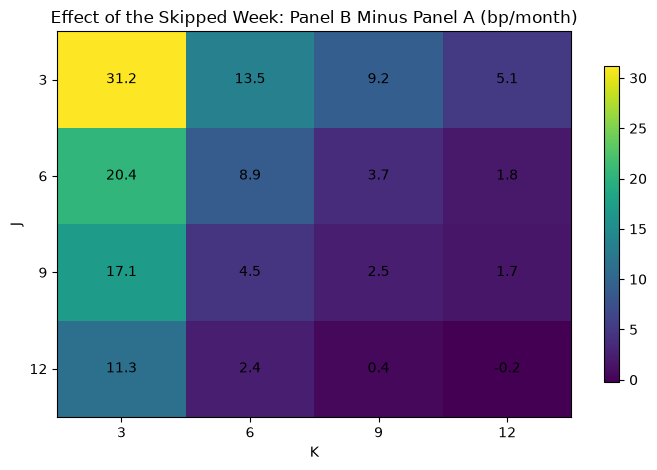

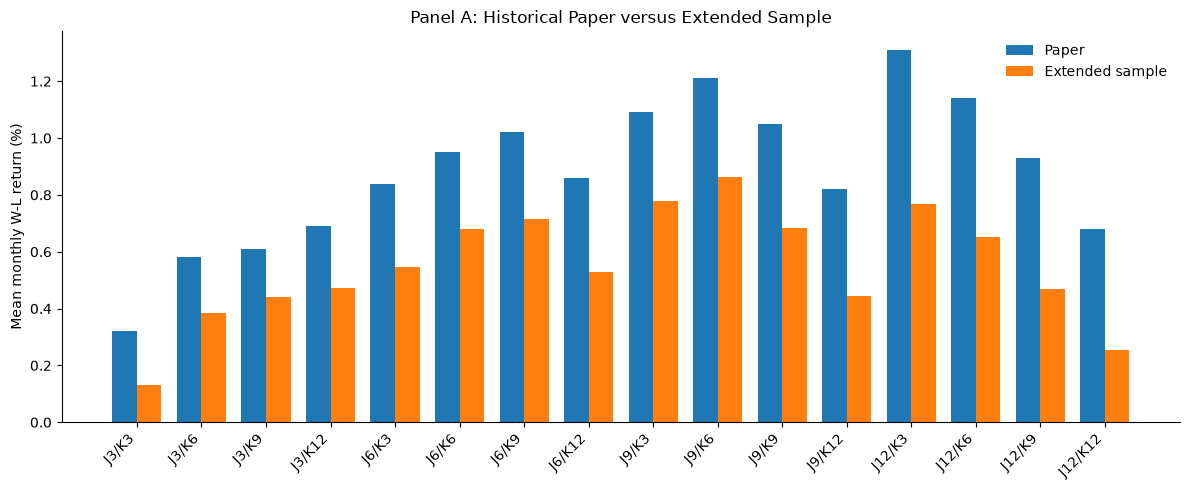

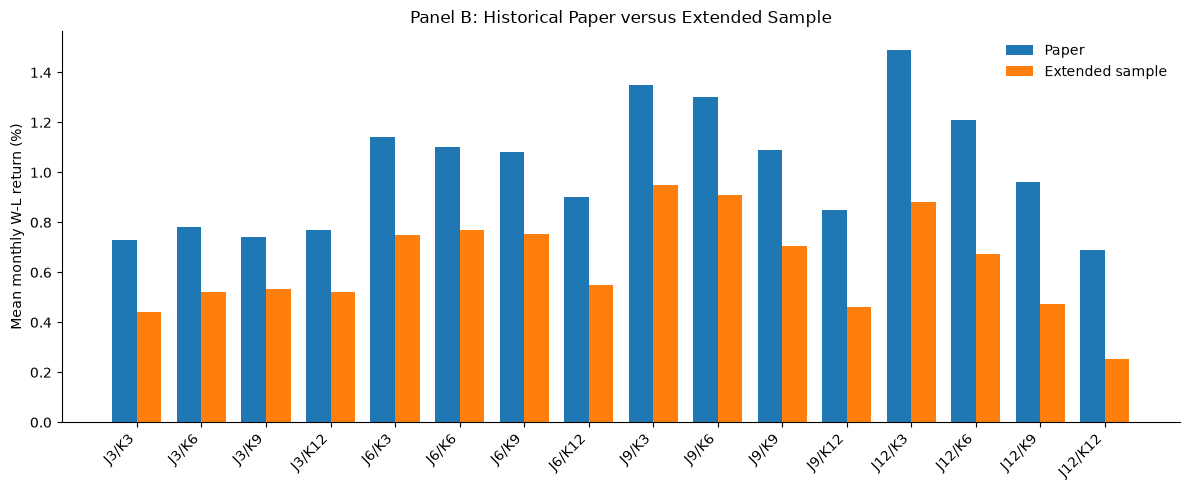

In [10]:
# ============================================================
# Logic
# 1. Format Table I in the paper's Sell / Buy / Buy-Sell layout.
# 2. Compare every paper and replication cell.
# 3. Plot return levels, deviations, and the Panel B-minus-A change.
#
# Output:
#   table_a_paper, table_a_rep, table_b_paper, table_b_rep, alignment
# ============================================================


def compact_panel(compare, source="rep"):
    mean_col = "rep_mean" if source == "rep" else "paper_mean"
    t_col = "rep_t" if source == "rep" else "paper_t"
    means = compare.pivot_table(index=["J", "leg"], columns="K", values=mean_col)
    tstats = compare.pivot_table(index=["J", "leg"], columns="K", values=t_col)
    names = {"loser": "Sell", "winner": "Buy", "buy_sell": "Buy-Sell"}
    rows = []

    for J in JS:
        for leg in ["loser", "winner", "buy_sell"]:
            row = {"J": J, "Portfolio": names[leg]}
            for K in KS:
                row[f"K={K}"] = f"{means.loc[(J, leg), K]:.4f} ({tstats.loc[(J, leg), K]:.2f})"
            rows.append(row)

    return pd.DataFrame(rows)


def wl_matrix(compare, value):
    return (compare.loc[compare["leg"].eq("buy_sell")]
                   .pivot(index="J", columns="K", values=value)
                   .reindex(index=JS, columns=KS))


def alignment_row(compare, name):
    wl = compare.loc[compare["leg"].eq("buy_sell")]
    return {
        "Panel": name,
        "MAE all returns (bp/month)": compare["diff_bp"].abs().mean(),
        "Maximum absolute difference (bp/month)": compare["diff_bp"].abs().max(),
        "MAE W-L (bp/month)": wl["diff_bp"].abs().mean(),
        "Maximum W-L difference (bp/month)": wl["diff_bp"].abs().max(),
        "MAE t-statistic": compare["t_diff"].abs().mean(),
        f"All series have {EXPECTED_MONTHS} months": bool(compare["n"].eq(EXPECTED_MONTHS).all()),
    }


table_a_paper = compact_panel(panel_a_compare, "paper")
table_a_rep = compact_panel(panel_a_compare, "rep")
table_b_paper = compact_panel(panel_b_compare, "paper")
table_b_rep = compact_panel(panel_b_compare, "rep")

print("Panel A — published Table I: mean monthly return (t-statistic)")
display(table_a_paper)
print("Panel A — replication: mean monthly return (t-statistic)")
display(table_a_rep)
print("Panel A — replication minus paper: W-L basis points per month")
display(wl_matrix(panel_a_compare, "diff_bp"))

print("Panel B — published Table I: mean monthly return (t-statistic)")
display(table_b_paper)
print("Panel B — replication: mean monthly return (t-statistic)")
display(table_b_rep)
print("Panel B — replication minus paper: W-L basis points per month")
display(wl_matrix(panel_b_compare, "diff_bp"))

alignment = pd.DataFrame([
    alignment_row(panel_a_compare, "Panel A"),
    alignment_row(panel_b_compare, "Panel B"),
])
display(alignment)

largest = pd.concat([panel_a_compare, panel_b_compare], ignore_index=True)
largest = largest.sort_values("diff_bp", key=lambda s: s.abs(), ascending=False)
print("Ten largest return differences")
display(largest[["panel", "J", "K", "leg", "rep_mean", "paper_mean", "diff_bp", "rep_t", "paper_t"]].head(10))

wl_a_rep = wl_matrix(panel_a_compare, "rep_mean")
wl_b_rep = wl_matrix(panel_b_compare, "rep_mean")
wl_a_diff = wl_matrix(panel_a_compare, "diff_bp")
wl_b_diff = wl_matrix(panel_b_compare, "diff_bp")

plot_heatmap(wl_a_rep * 100, "Panel A Replicated W-L Return (%)", value_fmt=".2f")
plot_heatmap(wl_b_rep * 100, "Panel B Replicated W-L Return (%)", value_fmt=".2f")
plot_heatmap(wl_a_diff, "Panel A: Extended Sample Minus Historical Paper (bp/month)", value_fmt=".1f")
plot_heatmap(wl_b_diff, "Panel B: Extended Sample Minus Historical Paper (bp/month)", value_fmt=".1f")
plot_heatmap((wl_b_rep - wl_a_rep) * 10_000,
             "Effect of the Skipped Week: Panel B Minus Panel A (bp/month)", value_fmt=".1f")


def plot_paper_vs_rep(compare, title):
    x = compare.loc[compare["leg"].eq("buy_sell")].sort_values(["J", "K"]).copy()
    labels = [f"J{j}/K{k}" for j, k in zip(x["J"], x["K"])]
    pos = np.arange(len(x))
    width = 0.38

    fig, ax = plt.subplots(figsize=(12, 5.0))
    ax.bar(pos - width / 2, x["paper_mean"] * 100, width, label="Paper")
    ax.bar(pos + width / 2, x["rep_mean"] * 100, width, label="Extended sample")
    ax.set_xticks(pos, labels=labels, rotation=45, ha="right")
    ax.set_ylabel("Mean monthly W-L return (%)")
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()


plot_paper_vs_rep(panel_a_compare, "Panel A: Historical Paper versus Extended Sample")
plot_paper_vs_rep(panel_b_compare, "Panel B: Historical Paper versus Extended Sample")


## 8. Interpretation and replication limits

### What the published Table I is designed to show

The paper reports positive Buy-minus-Sell returns across all 32 strategies. The largest published mean is the \(J=12, K=3\) strategy: **1.31% per month in Panel A** and **1.49% per month in Panel B**. The \(J=6\) strategies earn roughly 1% per month across holding horizons. Panel B is not a different economic strategy; it demonstrates that the momentum result remains after removing the final preformation week.

### How to evaluate this replication

A strong replication should reproduce the signs, cross-strategy pattern, economic magnitude, and inference—not select undocumented assumptions solely because they minimize one cell's error. The most important residual differences are likely to come from:

1. revisions to the historical CRSP database since the early 1990s;
2. the modern common-share restriction;
3. the unreported tie convention;
4. the exact calendar interpretation of “one week”;
5. treatment of missing and delisting-period returns.

The comparison tables express return differences in basis points per month so that economically small deviations remain visible.


In [11]:
# ============================================================
# Logic
# Save compact tables, long comparisons, timing checks, and checkpoints.
# ============================================================

outputs = {
    "panel_a_paper.csv": table_a_paper,
    "panel_a_replication.csv": table_a_rep,
    "panel_b_paper.csv": table_b_paper,
    "panel_b_replication.csv": table_b_rep,
    "panel_a_comparison_long.csv": panel_a_compare,
    "panel_b_comparison_long.csv": panel_b_compare,
    "alignment_summary.csv": alignment,
    "panel_b_timing_check.csv": panel_b_timing_check(J=6, n=12),
    "panel_a_6x6_monthly_returns.csv": plot_a66.rename_axis("month").reset_index(),
}

plot_b66 = ts_b66.copy()
plot_b66.index = month_id_to_month_end(plot_b66.index).to_numpy()
outputs["panel_b_6x6_monthly_returns.csv"] = plot_b66.rename_axis("month").reset_index()

for name, frame in outputs.items():
    frame.to_csv(RESULT / name, index=False)

print("Saved files:")
for name in outputs:
    print(" -", RESULT / name)


Saved files:
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_a_paper.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_a_replication.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_b_paper.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_b_replication.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_a_comparison_long.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_b_comparison_long.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\alignment_summary.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_b_timing_check.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_a_6x6_monthly_returns.csv
 - C:\Users\phil_prod\jt1993_table1_results_v3_2024\panel_b_6x6_monthly_returns.csv


## 9. Sensitivity checks

Change one convention at a time and rerun the affected cells:

- `DECILE_METHOD = "sas"` versus `"first"`;
- `FILL_MISSING_MONTHLY_RET = False` versus `True`;
- Panel B gap of 4, 5, 6, or 7 trading days;
- common shares only versus all NYSE/AMEX securities;
- an explicit modern CRSP delisting-return adjustment as a separate robustness exercise.

Keep the paper-aligned baseline fixed in the main table. Report sensitivity results as diagnostics rather than silently choosing the specification with the smallest numerical error.
